# Laboratório guiado: AutoML, TPOT e FLAML — Iris e dataset independente
**Disciplina:** Data Science e Inteligência Artificial  
**Ambiente:** Google Colab | **Linguagem:** Python | **Modalidade:** prática orientada + investigação autônoma

**Questão de pesquisa:** qual classificador oferece o melhor equilíbrio entre desempenho, estabilidade, interpretabilidade e custo computacional? O AutoML melhora a escolha?

**Entregas:** notebook executado, tabelas, gráficos, respostas argumentadas e experimento independente com outro conjunto de dados. **Não altere a divisão de teste para melhorar resultados.**

> **Como estudar:** execute uma célula por vez, leia a explicação imediatamente anterior e observe a saída antes de avançar. Os códigos foram divididos em passos curtos para facilitar a compreensão e a identificação de erros.

## Roteiro e regras de validade
1. Compreender e explorar os dados; 2. Reservar 20% como teste estratificado; 3. Comparar classificadores por validação cruzada **somente no treino**; 4. Ajustar FLAML e TPOT **somente no treino**; 5. Avaliar os finalistas uma única vez no teste; 6. Interpretar erros, tempos e estabilidade; 7. Repetir o estudo em dataset próprio.

**Cuidados:** não ajustar normalização, imputação ou seleção de atributos no conjunto completo; não usar o teste para escolher hiperparâmetros; não afirmar superioridade universal com base em Iris. A busca interna de AutoML não é diretamente comparável à validação cruzada externa: por isso, registraremos o protocolo e faremos uma comparação exploratória padronizada dos modelos selecionados.

**Tempo estimado:** 2–4 horas, conforme recursos e orçamento do AutoML. Em Colab, bibliotecas podem mudar e exigir reinicialização do ambiente.

## 0. Preparação do ambiente — TPOT 1.1.0
A versão atual do TPOT usa uma API diferente da versão 0.12.x. **Reinicie a sessão do Colab antes da instalação** se tiver executado o TPOT antigo. Após instalar, reinicie o ambiente de execução e prossiga a partir das importações. Não use `-U` indiscriminadamente para atualizar o scikit-learn depois de instalar TPOT.

A instalação e o treino completo dependem do ambiente e devem ser verificados no Colab antes da aula.

In [ ]:
%pip install -q "TPOT==1.1.0" "flaml[automl]" seaborn matplotlib pandas

**Depois da instalação:** no Colab, selecione **Ambiente de execução → Reiniciar sessão** e execute novamente o notebook. Se uma dependência gerar conflito, não prossiga com o treino até resolver a instalação.

**Passo — Bibliotecas.** Importamos apenas os recursos necessários para esta parte da análise. Execute esta célula antes das próximas.

In [1]:
import sys, platform, time, warnings, inspect, importlib.metadata as meta
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display
from sklearn import __version__ as sklearn_version
SEED=42
np.random.seed(SEED)
print('Python:',sys.version.split()[0], '| scikit-learn:',sklearn_version)

Python: 3.13.7 | scikit-learn: 1.9.1


## Acessibilidade dos gráficos — leitura sem depender de cores
Este notebook foi adaptado para estudantes com daltonismo e para projeção/impressão em preto e branco. Nos gráficos, **a cor nunca é a única forma de identificar uma categoria**: usamos formas geométricas, rótulos, valores numéricos e contornos. A paleta azul–laranja–verde é uma opção de alto contraste, mas **não substitui** os marcadores e textos. Matrizes de correlação e confusão mostram os números diretamente.

**Verificação sugerida:** observe os gráficos em escala de cinza e confirme que consegue identificar todas as classes e interpretar os valores. Evite interpretar diferenças apenas pela tonalidade.


**Passo — Execução e verificação.** Este bloco executa a operação descrita na seção e registra ou verifica seus resultados. Examine a saída antes de continuar.

In [2]:
for p in ['flaml','tpot','pandas','numpy']:
    try: print(p,meta.version(p))
    except Exception as e: print(p,'indisponível:',e)

flaml 2.8.0
tpot 1.1.0
pandas 3.1.1
numpy 2.5.4


## 1. Entendendo Iris
São **150 observações**, 3 classes equilibradas e 4 medidas morfológicas em centímetros. As espécies são *setosa*, *versicolor* e *virginica*. **Variáveis preditoras** são as medidas; **alvo** é a espécie. Pergunta: quais medidas parecem discriminar melhor as espécies?

In [3]:
from sklearn.datasets import load_iris
iris=load_iris(as_frame=True)
df=iris.frame.copy()
features=list(iris.feature_names)
target='target'
df['species']=df[target].map(dict(enumerate(iris.target_names)))
display(df.head(),df[features].describe(),df['species'].value_counts().rename('n'))
print('Ausências:',df[features+[target]].isna().sum().to_dict())

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


species
setosa        50
versicolor    50
virginica     50
Name: n, dtype: int64

Ausências: {'sepal length (cm)': 0, 'sepal width (cm)': 0, 'petal length (cm)': 0, 'petal width (cm)': 0, 'target': 0}


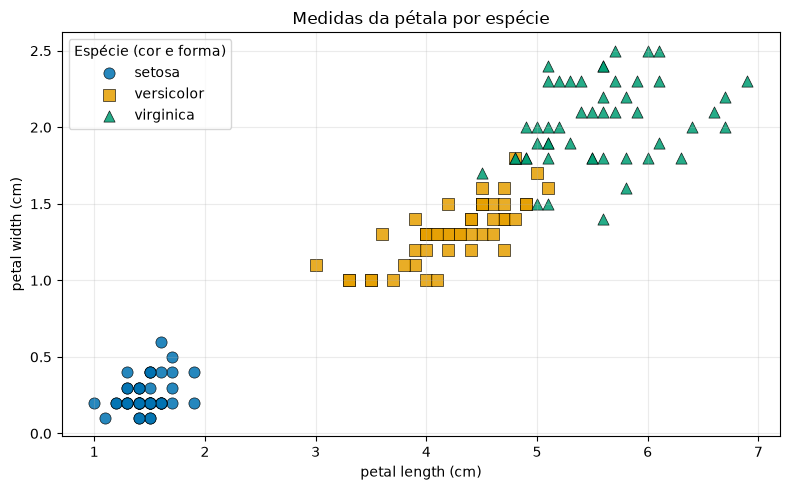

In [4]:
# Cada espécie recebe uma forma diferente, além de uma cor.
fig, ax = plt.subplots(figsize=(8, 5))
formas = ['o', 's', '^']
cores = ['#0072B2', '#E69F00', '#009E73']
for especie, forma, cor in zip(iris.target_names, formas, cores):
    dados = df[df['species'] == especie]
    ax.scatter(dados[features[2]], dados[features[3]],
               marker=forma, color=cor, edgecolor='black',
               linewidth=0.5, s=65, alpha=0.85, label=especie)
ax.set(xlabel=features[2], ylabel=features[3], title='Medidas da pétala por espécie')
ax.legend(title='Espécie (cor e forma)')
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()


### Leitura acessível do gráfico de dispersão
Cada espécie possui **uma forma própria**: círculo (*setosa*), quadrado (*versicolor*) e triângulo (*virginica*). As cores são redundantes: o gráfico continua interpretável em preto e branco. **Pergunta:** quais espécies se sobrepõem mais?


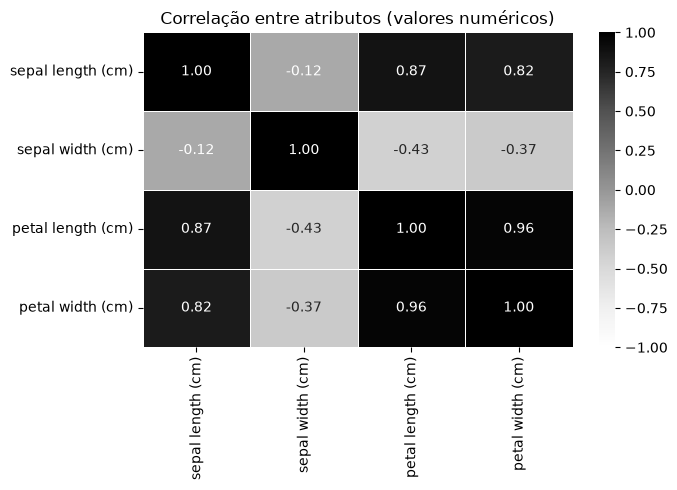

In [5]:
# A correlação usa escala de cinza e valores escritos nas células.
plt.figure(figsize=(7, 5))
sns.heatmap(df[features].corr(), annot=True, fmt='.2f',
            cmap='Greys', vmin=-1, vmax=1,
            linewidths=0.7, linecolor='white')
plt.title('Correlação entre atributos (valores numéricos)')
plt.tight_layout()
plt.show()


**Responda:** (1) Há desequilíbrio entre classes? (2) Quais variáveis parecem mais informativas? (3) Correlação implica causalidade? (4) Por que uma boa separação visual não garante generalização?

Respostas:
1. Não, as 3 classes tem 50 exemplos cada, ta equilibrado.
2. As medidas da pétala (comprimento e largura). No gráfico a setosa fica totalmente separada e a correlação entre elas é bem alta (0.96).
3. Não. Correlação só mostra que as variaveis andam juntas, não que uma causa a outra.
4. Porque o gráfico mostra só os dados que a gente tem. Um modelo pode decorar esses dados e errar em flores novas, por isso precisa testar em dados que ele não viu.

## 2. Partição e métricas
Usaremos **80% treino / 20% teste**, estratificados. Durante a seleção, a validação cruzada estratificada em 5 folds é aplicada **apenas ao treino**. Métrica principal: **F1 macro**, que atribui peso igual a cada classe. Métricas complementares: acurácia, precisão macro, recall macro, desvio-padrão entre folds e tempo de treinamento.

**Passo — Bibliotecas.** Importamos apenas os recursos necessários para esta parte da análise. Execute esta célula antes das próximas.

In [6]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay)
X=df[features].copy(); y=df[target].copy()
X=df[features].copy(); y=df[target].copy()
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.20,random_state=SEED,stratify=y)
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=SEED)
print('Treino:',X_train.shape,'Teste:',X_test.shape)

Treino: (120, 4) Teste: (30, 4)


**Passo — Inspeção.** Confira os valores exibidos e anote os resultados relevantes para a discussão.

In [7]:
print('Distribuição treino:',y_train.value_counts().sort_index().to_dict())
print('Distribuição teste:',y_test.value_counts().sort_index().to_dict())

Distribuição treino: {0: 40, 1: 40, 2: 40}
Distribuição teste: {0: 10, 1: 10, 2: 10}


## 3. Baselines manuais: diferentes famílias de classificadores
SVM e KNN dependem da escala, portanto a padronização é colocada **dentro do pipeline** e reajustada em cada fold. Árvores e ensembles de árvores normalmente dispensam padronização. Todos os modelos começam com hiperparâmetros de referência; isso **não equivale** a uma busca manual otimizada.

**Passo — Bibliotecas.** Importamos apenas os recursos necessários para esta parte da análise. Execute esta célula antes das próximas.

In [8]:
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier, HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

**Passo — Catálogo de algoritmos.** Definimos os classificadores a comparar. Observe quando a padronização está dentro de um `Pipeline`, evitando vazamento de informações.

In [9]:
models={
 'Logistic Regression':make_pipeline(StandardScaler(),LogisticRegression(max_iter=2000,random_state=SEED)),
 'SVM linear':make_pipeline(StandardScaler(),SVC(kernel='linear',random_state=SEED)),
 'SVM RBF':make_pipeline(StandardScaler(),SVC(kernel='rbf',random_state=SEED)),
 'Decision Tree':DecisionTreeClassifier(random_state=SEED),
 'Random Forest':RandomForestClassifier(n_estimators=200,random_state=SEED),
 'Gradient Boosting':GradientBoostingClassifier(random_state=SEED),
 'HistGradientBoosting':HistGradientBoostingClassifier(random_state=SEED),
 'AdaBoost':AdaBoostClassifier(random_state=SEED),
 'KNN':make_pipeline(StandardScaler(),KNeighborsClassifier()),
 'Gaussian NB':GaussianNB()
}

**Passo — Bibliotecas.** Importamos apenas os recursos necessários para esta parte da análise. Execute esta célula antes das próximas.

In [10]:
from sklearn.base import clone
def score_cv(model,Xtr,ytr,folds=cv):
    t=time.perf_counter()
    r=cross_validate(model,Xtr,ytr,cv=folds,scoring={'accuracy':'accuracy','f1_macro':'f1_macro','precision_macro':'precision_macro','recall_macro':'recall_macro'},n_jobs=1,error_score='raise')
    return {'CV F1 macro':r['test_f1_macro'].mean(),'CV F1 desvio':r['test_f1_macro'].std(),
            'CV acurácia':r['test_accuracy'].mean(),'CV precisão macro':r['test_precision_macro'].mean(),
            'CV recall macro':r['test_recall_macro'].mean(),'Tempo CV (s)':time.perf_counter()-t}
manual_rows=[]

**Passo — Execução e verificação.** Este bloco executa a operação descrita na seção e registra ou verifica seus resultados. Examine a saída antes de continuar.

In [11]:
for name,model in models.items():
    try:manual_rows.append({'Modelo':name,**score_cv(model,X_train,y_train)})
    except Exception as e:print('Falha em',name,repr(e))
manual_table=pd.DataFrame(manual_rows).sort_values('CV F1 macro',ascending=False)
display(manual_table.round(4))

,Modelo,CV F1 macro,CV F1 desvio,CV acurácia,CV precisão macro,CV recall macro,Tempo CV (s)
1,SVM linear,0.9747,0.0338,0.9750,0.9793,0.9750,0.0275
2,SVM RBF,0.9665,0.0167,0.9667,0.9704,0.9667,0.0256
0,Logistic Regression,0.9580,0.0268,0.9583,0.9644,0.9583,0.0495
8,KNN,0.9580,0.0268,0.9583,0.9644,0.9583,0.0312
3,Decision Tree,0.9496,0.0171,0.9500,0.9570,0.9500,0.0217
6,HistGradientBoosting,0.9496,0.0171,0.9500,0.9570,0.9500,0.7754
9,Gaussian NB,0.9496,0.0171,0.9500,0.9570,0.9500,0.0213
4,Random Forest,0.9494,0.0317,0.9500,0.9585,0.9500,0.4942
5,Gradient Boosting,0.9494,0.0317,0.9500,0.9585,0.9500,0.3580
7,AdaBoost,0.9327,0.0208,0.9333,0.9419,0.9333,0.1743


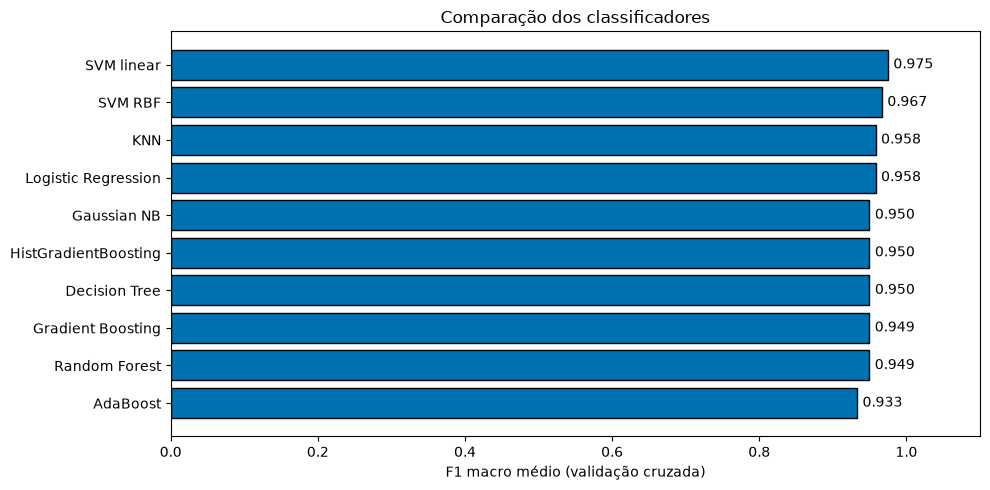

In [12]:
# Uma única cor é suficiente: os valores aparecem ao lado das barras.
ordenado = manual_table.sort_values('CV F1 macro')
fig, ax = plt.subplots(figsize=(10, 5))
barras = ax.barh(ordenado['Modelo'], ordenado['CV F1 macro'],
                 color='#0072B2', edgecolor='black')
ax.bar_label(barras, fmt='%.3f', padding=4)
ax.set(xlim=(0, 1.10), xlabel='F1 macro médio (validação cruzada)',
       title='Comparação dos classificadores')
plt.tight_layout()
plt.show()


**Interpretação:** o melhor valor médio difere do segundo colocado mais do que a variabilidade entre folds? Um único split de 30 amostras pode inverter a ordem dos modelos. Não confunda diferença numérica com evidência de superioridade estatística.

Resposta: o SVM linear ficou em 1º (0.9747) e o SVM RBF em 2º (0.9665). A diferença é de menos de 0.01, e o desvio do SVM linear é 0.034, então a diferença é menor que a variação entre os folds. Praticamente todos os modelos ficaram entre 0.93 e 0.97

## 4. AutoML com FLAML
FLAML usa uma estratégia eficiente de busca de algoritmos e hiperparâmetros. Configuramos orçamento de **60 segundos** (ajustável), F1 macro e validação cruzada estratificada em 5 folds. O orçamento é de busca, não garantia de duração exata. **FLAML pode não explorar todos os algoritmos manuais**; registre o espaço efetivamente disponível. Em Iris, 60 segundos pode ser insuficiente para algumas configurações.

**Compatibilidade no Colab:** esta atividade restringe a busca a LightGBM (`lgbm`), Random Forest (`rf`) e Extra Trees (`extra_tree`). O XGBoost foi retirado **somente da busca automática do FLAML**, pois certas combinações FLAML/XGBoost falham com `XGBClassifier.fit(..., callbacks=...)`. Isso não altera os modelos manuais nem o TPOT. A restrição deve ser mencionada na discussão; ela não garante compatibilidade com todas as versões futuras.

**Passo — Preparação.** Esta célula define os objetos e parâmetros usados na etapa seguinte. Observe os nomes das variáveis e seus valores.

In [13]:
FLAML_SECONDS=60  # Para uma exploração mais longa: 120–300
flaml_model=None; flaml_error=None; flaml_elapsed=None

**Passo — Execução e verificação.** Este bloco executa a operação descrita na seção e registra ou verifica seus resultados. Examine a saída antes de continuar.

In [14]:
try:
    from flaml import AutoML
    flaml_model=AutoML()
    t=time.perf_counter()
    flaml_model.fit(X_train=X_train,y_train=y_train,task='classification',metric='macro_f1',
                    estimator_list=['lgbm', 'rf', 'extra_tree'],
                    time_budget=FLAML_SECONDS,eval_method='cv',n_splits=5,
                    split_type='stratified',seed=SEED,verbose=0,n_jobs=1)
    flaml_elapsed=time.perf_counter()-t
    print('FLAML melhor estimador:',flaml_model.best_estimator)
    print('FLAML configuração:',flaml_model.best_config)
    print('Tempo (s):',round(flaml_elapsed,2))
except Exception as e:
    flaml_error=repr(e);flaml_model=None
    print('FLAML não concluiu:',flaml_error)
    print('Verifique compatibilidade da versão, dependências e métrica. Não invente resultado.')

/Users/pedrocm/Documents/UMC Eng_Soft/Semestre2/IA/Fabiano/AutoML/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


FLAML melhor estimador: extra_tree
FLAML configuração: {'n_estimators': 12, 'max_features': np.float64(0.9193497456735744), 'max_leaves': 4, 'criterion': np.str_('entropy')}
Tempo (s): 60.01


**Questões:** Qual estimador foi escolhido? Quais hiperparâmetros mudaram? O tempo foi respeitado aproximadamente? A ferramenta buscou todos os modelos da lista manual?

Respostas: o FLAML escolheu extra_tree (Extra Trees) com 12 árvores, max_leaves=4, max_features≈0.92 e criterio entropy. Usou 60s corretamewnte. Ele não buscou todos os modelos da lista manual, o FLAML tem o espaço dele (lgbm, rf, extra_tree, xgboost, lrl1...), não testa SVM, KNN nem Naive Bayes por exemplo.

## 5. AutoML com TPOT 1.1.0
O TPOT 1.1.0 usa **`scorers`** (lista de métricas) em vez de `scoring` da API antiga. Aqui usamos **F1 macro**, cinco folds, espaço `linear-light` para tornar a aula mais rápida e uma população pequena. O limite de tempo é aproximado; o TPOT pode demorar mais para inicializar e finalizar tarefas. O modelo será treinado **somente nos dados de treinamento**.

**Atenção:** execute esta seção em runtime limpo depois da instalação. Não altere a versão do scikit-learn após a instalação do TPOT.

**Passo — Preparação.** Esta célula define os objetos e parâmetros usados na etapa seguinte. Observe os nomes das variáveis e seus valores.

In [15]:
TPOT_MINUTES = 5  # Aumente para 10–15 no desafio final
TPOT_N_JOBS = 1  # Menor consumo de recursos no Colab

**Passo 1 — Conferir a versão.** A atividade utiliza exclusivamente a API 1.1.0; se aparecer outra versão, reinicie a sessão e refaça a instalação.

In [16]:
import importlib.metadata as metadata
print("TPOT instalado:", metadata.version("TPOT"))
assert metadata.version("TPOT") == "1.1.0", "Instale TPOT 1.1.0 e reinicie o runtime."

TPOT instalado: 1.1.0


**Passo 2 — Importar e configurar.** `scorers` recebe uma lista de métricas; `search_space="linear-light"` limita a complexidade para a aula.

In [17]:
from tpot import TPOTClassifier

tpot_model = TPOTClassifier(
    scorers=["f1_macro"],
    cv=cv,
    search_space="linear-light",
    population_size=12,
    generations=3,
    max_time_mins=TPOT_MINUTES,
    max_eval_time_mins=1,
    n_jobs=TPOT_N_JOBS,
    random_state=SEED,
    verbose=2
)

/Users/pedrocm/Documents/UMC Eng_Soft/Semestre2/IA/Fabiano/AutoML/.venv/lib/python3.13/site-packages/stopit/__init__.py:10: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


**Passo 3 — Treinar.** O TPOT procura pipelines por otimização evolutiva. A busca pode levar alguns minutos; não interrompa o treinamento.

In [18]:
tpot_error = None
tpot_elapsed = None
inicio_tpot = time.perf_counter()
try:
    tpot_model.fit(X_train, y_train)
    tpot_elapsed = time.perf_counter() - inicio_tpot
    print(f"TPOT concluído em {tpot_elapsed:.1f} s")
except Exception as exc:
    tpot_error = repr(exc)
    tpot_model = None
    raise RuntimeError("TPOT não concluiu. Veja o erro original acima.") from exc

/Users/pedrocm/Documents/UMC Eng_Soft/Semestre2/IA/Fabiano/AutoML/.venv/lib/python3.13/site-packages/tpot/tpot_estimator/estimator.py:458: UserWarning: Both generations and max_time_mins are set. TPOT will terminate when the first condition is met.
  warnings.warn("Both generations and max_time_mins are set. TPOT will terminate when the first condition is met.")



  0%|          | 0/3 [00:00<?, ?it/s]


Generation:   0%|          | 0/3 [00:00<?, ?it/s]

/Users/pedrocm/Documents/UMC Eng_Soft/Semestre2/IA/Fabiano/AutoML/.venv/lib/python3.13/site-packages/stopit/__init__.py:10: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources



Generation:  33%|███▎      | 1/3 [00:02<00:05,  2.67s/it]


Generation:  67%|██████▋   | 2/3 [00:03<00:01,  1.79s/it]


Generation: 100%|██████████| 3/3 [00:05<00:00,  1.63s/it]


Generation: 100%|██████████| 3/3 [00:05<00:00,  1.76s/it]

TPOT concluído em 6.5 s


**Passo 4 — Interpretar o pipeline selecionado.** Registre os algoritmos e transformações escolhidos e discuta se são mais complexos que o baseline.

In [19]:
if tpot_model is not None:
    print(tpot_model.fitted_pipeline_)

Pipeline(steps=[('maxabsscaler', MaxAbsScaler()),
                ('selectfwe', SelectFwe(alpha=0.0001388455008)),
                ('featureunion-1',
                 FeatureUnion(transformer_list=[('featureunion',
                                                 FeatureUnion(transformer_list=[('fastica',
                                                                                 FastICA(algorithm=np.str_('parallel'),
                                                                                         n_components=1,
                                                                                         random_state=42)),
                                                                                ('columnordinalencoder',
                                                                                 ColumnOrdinalEncoder())])),
                                                ('passthrough',
                                                 Passthrough())])),
              

**Atenção metodológica:** TPOT pode empregar estratégias de otimização e CV distintas das do FLAML. Mesmo usando F1 macro, os valores internos não são automaticamente comparáveis. O conjunto de teste externo é comum aos finalistas. O orçamento temporal e o espaço de busca devem ser descritos no relatório.

Registro do TPOT: rodou com o TPOT 1.1.0. Ele parou nas 3 gerações em +- 7 segundos, bem antes dos 5 minutos. O pipeline escolhido foi um KNeighborsClassifier (n_neighbors=12, p=3) com um pré-processamento com FastICA (1 componentes) junto das variavei originais. É mais complicado que os baselines e não precisava, o KNN simples ja ia bem.

## 6. Comparação dos finalistas no conjunto de teste intocado
Selecionamos o melhor modelo manual **pela F1 macro média de CV**; em seguida avaliamos uma única vez cada finalista no mesmo conjunto de teste. O desempenho do teste **não deve ser usado para reabrir a busca**. Resultados de TPOT e FLAML só aparecem se realmente executados.

In [20]:
best_manual_name=manual_table.iloc[0]['Modelo']
finalists={f'Manual: {best_manual_name}':clone(models[best_manual_name])}
if flaml_model is not None:finalists['FLAML']=flaml_model
if tpot_model is not None:finalists['TPOT']=tpot_model
final_rows={}; predictions={}
for name,model in finalists.items():
    try:
        start=time.perf_counter()
        if name.startswith('Manual:'):model.fit(X_train,y_train)
        pred=model.predict(X_test)
        pred=np.asarray(pred).reshape(-1)
        final_rows[name]={'Acurácia teste':accuracy_score(y_test,pred),
                          'F1 macro teste':f1_score(y_test,pred,average='macro'),
                          'Tempo avaliação (s)':time.perf_counter()-start}
        predictions[name]=pred
        print('\n',name)
        print(classification_report(y_test,pred,target_names=iris.target_names,zero_division=0))
    except Exception as e:print('Falha na avaliação de',name,repr(e))
final_table=pd.DataFrame.from_dict(final_rows,orient='index')
display(final_table.round(4))


 Manual: SVM linear
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00        10
   virginica       1.00      1.00      1.00        10

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30


 FLAML
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30


 TPOT
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      

,Acurácia teste,F1 macro teste,Tempo avaliação (s)
Manual: SVM linear,1.0000,1.0000,0.0046
FLAML,0.9333,0.9333,0.0039
TPOT,0.9333,0.9333,0.0033


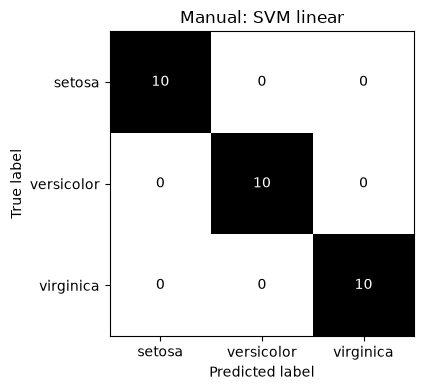

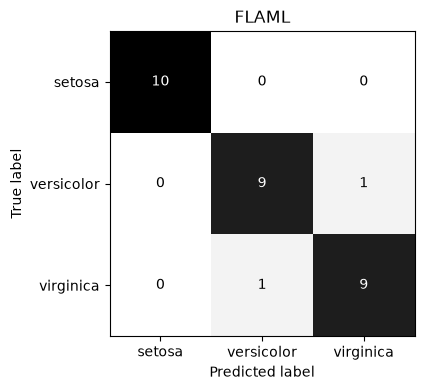

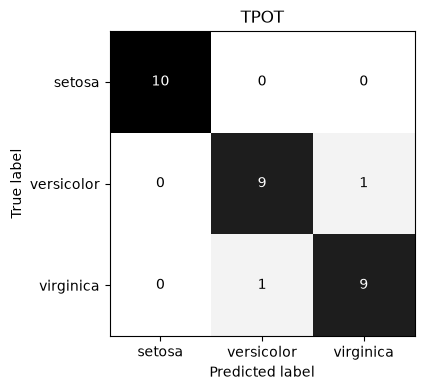

In [21]:
# Intensidade em cinza + números em cada célula.
for name, pred in predictions.items():
    fig, ax = plt.subplots(figsize=(5, 4))
    ConfusionMatrixDisplay.from_predictions(
        y_test, pred, display_labels=iris.target_names,
        cmap='Greys', values_format='d', ax=ax,
        colorbar=False)
    ax.set_title(name)
    plt.tight_layout()
    plt.show()


### Interpretação obrigatória
1. Qual foi o melhor baseline manual **na validação cruzada**? 2. Quais modelos erraram *versicolor* e *virginica*? 3. TPOT/FLAML superaram o baseline no teste? 4. A diferença é substantiva considerando apenas 30 exemplos de teste? 5. Qual seria sua escolha se interpretabilidade e custo importassem? 6. Quais limitações impedem generalizar a conclusão para outros datasets?

Respostas:
1. SVM linear (F1 CV 0.9747).
2. O SVM linear não errou nada no teste. O FLAML e o TPOT erraram 2 cada: uma versicolor como virginica e uma virginica como versicolor.
3. Não. Manual F1 1.0, FLAML 0.9333 e TPOT 0.9333.
4. Não é. Com 30 exemplos, 1 erro ja muda a acurácia em 3.3%.
5. Regressão logística ou SVM linear, são simples, rapidos e da pra entender os pesos.
6. O Iris é pequeno, limpo, equilibrado e quase separavel, então quase todo modelo vai bem. Isso não vale pra outros datasets.

## 7. Estabilidade: repetir a validação cruzada
Uma única partição pode favorecer um modelo. Usaremos validação cruzada repetida (5 folds × 3 repetições) **apenas para os modelos manuais de referência**, sem utilizar o conjunto de teste. Esta etapa é uma análise adicional de estabilidade; não substitui uma avaliação aninhada para comparar buscas de hiperparâmetros.

In [22]:
from sklearn.model_selection import RepeatedStratifiedKFold
rcv=RepeatedStratifiedKFold(n_splits=5,n_repeats=3,random_state=SEED)
stability=[]
for name,model in models.items():
    r=cross_validate(model,X_train,y_train,cv=rcv,scoring='f1_macro',n_jobs=1)
    stability.append({'Modelo':name,'F1 médio':r['test_score'].mean(),
                      'F1 desvio':r['test_score'].std(),'F1 mínimo':r['test_score'].min()})
stability_df=pd.DataFrame(stability).sort_values('F1 médio',ascending=False)
display(stability_df.round(4))

,Modelo,F1 médio,F1 desvio,F1 mínimo
2,SVM RBF,0.9664,0.0276,0.9153
1,SVM linear,0.9635,0.0431,0.8745
0,Logistic Regression,0.9579,0.0309,0.9153
8,KNN,0.9553,0.0242,0.9153
4,Random Forest,0.9521,0.0378,0.8704
6,HistGradientBoosting,0.9494,0.0387,0.8704
3,Decision Tree,0.9491,0.0392,0.8704
9,Gaussian NB,0.9468,0.0243,0.9153
5,Gradient Boosting,0.9461,0.0456,0.8704
7,AdaBoost,0.9379,0.0438,0.8704


---
# PARTE II — Desafio independente: escolha seu próprio dataset
**Missão:** selecionar um conjunto público de dados de **classificação supervisionada**, justificar a escolha e reproduzir o experimento. **Não escolha um dataset de regressão** para este roteiro. Recomendação didática: pelo menos 150 amostras, duas ou mais classes, alvo claramente definido, licença e origem documentadas. Evite dados sensíveis ou identificáveis. Exemplos possíveis: Wine, Breast Cancer Wisconsin (Diagnostic), Digits ou um CSV público de classificação.

**Antes de executar:** documente fonte/URL, licença, data de acesso, unidade amostral, variável alvo, significado das classes, variáveis, ausências, duplicatas, possível vazamento e limitações. Para dados médicos, resultados são apenas educacionais e não constituem validação clínica.

## 8. Carregar um novo dataset
Escolha **uma** das opções: `wine`, `breast_cancer`, `digits` ou `csv`. Para CSV, envie o arquivo no Colab e informe a coluna alvo. **Nesta versão da atividade, são aceitas variáveis preditoras numéricas**; variáveis categóricas exigem um pipeline adicional de codificação ajustado apenas no treino.

**Passo — Preparação.** Esta célula define os objetos e parâmetros usados na etapa seguinte. Observe os nomes das variáveis e seus valores.

In [23]:
DATASET='wine'  # 'wine', 'breast_cancer', 'digits' ou 'csv'
CSV_TARGET='classe'  # Modifique se DATASET='csv'

**Passo — Execução e verificação.** Este bloco executa a operação descrita na seção e registra ou verifica seus resultados. Examine a saída antes de continuar.

In [24]:
if DATASET in ('wine','breast_cancer','digits'):
    from sklearn.datasets import load_wine,load_breast_cancer,load_digits
    loader={'wine':load_wine,'breast_cancer':load_breast_cancer,'digits':load_digits}[DATASET]
    ds=loader(as_frame=True)
    X2=ds.data.copy(); y2=ds.target.copy()
    source=f'scikit-learn: {DATASET}'
elif DATASET=='csv':
    from google.colab import files
    uploaded=files.upload()
    if len(uploaded)!=1:raise ValueError('Envie exatamente um arquivo CSV.')
    filename=next(iter(uploaded))
    raw=pd.read_csv(filename)
    if CSV_TARGET not in raw:raise ValueError(f'Alvo {CSV_TARGET!r} ausente: {list(raw.columns)}')
    y2=raw[CSV_TARGET].copy();X2=raw.drop(columns=[CSV_TARGET]).copy()
    source=filename
else:raise ValueError('Escolha uma das quatro opções.')

**Passo — Execução e verificação.** Este bloco executa a operação descrita na seção e registra ou verifica seus resultados. Examine a saída antes de continuar.

In [25]:
if y2.isna().any():raise ValueError('O alvo contém valores ausentes; revise o dataset.')
if not all(pd.api.types.is_numeric_dtype(t) for t in X2.dtypes):
    raise ValueError('Existem preditores não numéricos. Codifique-os com ColumnTransformer dentro de um pipeline antes de prosseguir.')
if y2.nunique()<2:raise ValueError('Classificação exige pelo menos duas classes.')
print('Fonte:',source,'| X:',X2.shape,'| classes:',y2.nunique())
display(X2.head(),y2.value_counts().rename('n'),X2.isna().sum().sort_values(ascending=False).head(10))

Fonte: scikit-learn: wine | X: (178, 13) | classes: 3


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


target
1    71
0    59
2    48
Name: n, dtype: int64

alcohol                 0
malic_acid              0
ash                     0
alcalinity_of_ash       0
magnesium               0
total_phenols           0
flavanoids              0
nonflavanoid_phenols    0
proanthocyanins         0
color_intensity         0
dtype: int64

## 9. Preparação e baselines no dataset escolhido
Usaremos imputação de medianas **dentro de cada pipeline** para não vazar informação. A etapa de AutoML exige cuidado adicional com ausências: para simplificar, o exercício usa um pipeline de imputação **ajustado apenas no treino** antes do AutoML. Em uma análise rigorosa, a imputação deve ser integrada ao processo interno de CV do AutoML; por isso, se houver ausências, recomendamos selecionar outro dataset completo para a comparação principal ou configurar a ferramenta com pipeline apropriado.

**Passo — Bibliotecas.** Importamos apenas os recursos necessários para esta parte da análise. Execute esta célula antes das próximas.

In [26]:
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
labels=LabelEncoder();y2_encoded=labels.fit_transform(y2.astype(str))
labels=LabelEncoder();y2_encoded=labels.fit_transform(y2.astype(str))
counts=pd.Series(y2_encoded).value_counts()
if counts.min()<5:raise ValueError('Cada classe precisa ter pelo menos 5 exemplos para este protocolo de CV.')

**Passo — Execução e verificação.** Este bloco executa a operação descrita na seção e registra ou verifica seus resultados. Examine a saída antes de continuar.

In [27]:
if X2.isna().any().any():
    print('ATENÇÃO: há ausências. Baselines tratam com imputação em pipeline; AutoML será bloqueado abaixo para evitar CV com vazamento.')
X2tr,X2te,y2tr,y2te=train_test_split(X2,y2_encoded,test_size=.20,stratify=y2_encoded,random_state=SEED)
if pd.Series(y2tr).value_counts().min()<5:raise ValueError('Treino insuficiente para CV estratificada de 5 folds.')
models2={name:make_pipeline(SimpleImputer(strategy='median'),clone(model)) for name,model in models.items()}
rows2=[]
for name,model in models2.items():
    try:rows2.append({'Modelo':name,**score_cv(model,X2tr,y2tr)})
    except Exception as e:print('Falha:',name,repr(e))

**Passo — Preparação.** Esta célula define os objetos e parâmetros usados na etapa seguinte. Observe os nomes das variáveis e seus valores.

In [28]:
results2=pd.DataFrame(rows2).sort_values('CV F1 macro',ascending=False)
display(results2.round(4))

,Modelo,CV F1 macro,CV F1 desvio,CV acurácia,CV precisão macro,CV recall macro,Tempo CV (s)
2,SVM RBF,0.9865,0.0167,0.9862,0.9865,0.9878,0.0271
1,SVM linear,0.9863,0.0274,0.9862,0.9856,0.9889,0.0281
0,Logistic Regression,0.9796,0.0273,0.9791,0.9789,0.9828,0.0336
4,Random Forest,0.9789,0.0285,0.9791,0.9785,0.9828,0.5326
9,Gaussian NB,0.9727,0.0266,0.9722,0.9734,0.9762,0.0223
6,HistGradientBoosting,0.9600,0.0338,0.9581,0.9597,0.9645,0.8299
8,KNN,0.9512,0.0365,0.9507,0.9526,0.9591,0.0284
7,AdaBoost,0.9451,0.0274,0.9441,0.9500,0.9465,0.1888
5,Gradient Boosting,0.9259,0.1000,0.9236,0.9379,0.9310,0.5635
3,Decision Tree,0.9055,0.0569,0.9022,0.9128,0.9113,0.0234


## 10. FLAML e TPOT no dataset independente
Por segurança metodológica, esta implementação exige **ausência de valores faltantes** para AutoML. Se seu dataset contém ausências, documente a limitação e use outro dataset completo ou, com orientação docente, adapte os pipelines de busca para incluir imputação dentro dos folds.

**Mesma configuração do Iris:** a busca do FLAML neste segundo dataset também exclui XGBoost para evitar o erro de `callbacks`. Os estudantes devem registrar essa restrição metodológica.

**Passo — Execução e verificação.** Este bloco executa a operação descrita na seção e registra ou verifica seus resultados. Examine a saída antes de continuar.

In [29]:
if X2.isna().any().any():
    raise ValueError('AutoML bloqueado: existem ausências. Evite imputar o conjunto todo antes da CV interna.')
FLAML_SECONDS_2=90
flaml2=None;tpot2=None

**Passo — Execução e verificação.** Este bloco executa a operação descrita na seção e registra ou verifica seus resultados. Examine a saída antes de continuar.

In [30]:
try:
    from flaml import AutoML
    flaml2=AutoML()
    flaml2.fit(X_train=X2tr,y_train=y2tr,task='classification',metric='macro_f1',
               estimator_list=['lgbm', 'rf', 'extra_tree'],
               time_budget=FLAML_SECONDS_2,eval_method='cv',n_splits=5,
               split_type='stratified',seed=SEED,verbose=0,n_jobs=1)
    print('FLAML:',flaml2.best_estimator,flaml2.best_config)
except Exception as e:
    print('FLAML falhou:',repr(e));flaml2=None

FLAML: extra_tree {'n_estimators': 12, 'max_features': np.float64(0.2079850173607416), 'max_leaves': 7, 'criterion': np.str_('gini')}


**Passo — Execução e verificação.** Este bloco executa a operação descrita na seção e registra ou verifica seus resultados. Examine a saída antes de continuar.

**Passo 1 — Criar o TPOT para o dataset escolhido.** Mantemos a mesma métrica F1 macro, mas reservamos mais tempo para a busca.

In [31]:
tpot2 = TPOTClassifier(
    scorers=["f1_macro"], cv=cv,
    search_space="linear-light",
    population_size=12, generations=3,
    max_time_mins=5, max_eval_time_mins=1,
    n_jobs=1, random_state=SEED, verbose=2
)

**Passo 2 — Treinar no conjunto de treinamento do novo dataset.** Se ocorrer erro, ele será exibido para diagnóstico; não registre desempenho inexistente.

In [32]:
try:
    tpot2.fit(X2tr, y2tr)
    print("TPOT concluiu o treinamento.")
except Exception as exc:
    tpot2 = None
    raise RuntimeError("Falha do TPOT no dataset independente") from exc

/Users/pedrocm/Documents/UMC Eng_Soft/Semestre2/IA/Fabiano/AutoML/.venv/lib/python3.13/site-packages/tpot/tpot_estimator/estimator.py:458: UserWarning: Both generations and max_time_mins are set. TPOT will terminate when the first condition is met.
  warnings.warn("Both generations and max_time_mins are set. TPOT will terminate when the first condition is met.")



  0%|          | 0/3 [00:00<?, ?it/s]


Generation:   0%|          | 0/3 [00:00<?, ?it/s]

/Users/pedrocm/Documents/UMC Eng_Soft/Semestre2/IA/Fabiano/AutoML/.venv/lib/python3.13/site-packages/stopit/__init__.py:10: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources



Generation:  33%|███▎      | 1/3 [00:02<00:05,  2.94s/it]


Generation:  67%|██████▋   | 2/3 [00:04<00:02,  2.13s/it]


Generation: 100%|██████████| 3/3 [00:05<00:00,  1.80s/it]


Generation: 100%|██████████| 3/3 [00:05<00:00,  1.97s/it]


/Users/pedrocm/Documents/UMC Eng_Soft/Semestre2/IA/Fabiano/AutoML/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/pedrocm/Documents/UMC Eng_Soft/Semestre2/IA/Fabiano/AutoML/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


TPOT concluiu o treinamento.


**Passo 3 — Inspecionar o modelo escolhido.** Compare o pipeline com os algoritmos manuais e o FLAML.

In [33]:
if tpot2 is not None:
    print(tpot2.fitted_pipeline_)

Pipeline(steps=[('minmaxscaler', MinMaxScaler()),
                ('variancethreshold',
                 VarianceThreshold(threshold=0.0378168026136)),
                ('featureunion-1',
                 FeatureUnion(transformer_list=[('skiptransformer',
                                                 SkipTransformer()),
                                                ('passthrough',
                                                 Passthrough())])),
                ('featureunion-2',
                 FeatureUnion(transformer_list=[('skiptransformer',
                                                 SkipTransformer()),
                                                ('passthrough',
                                                 Passthrough())])),
                ('logisticregression',
                 LogisticRegression(C=3.4016074980411, l1_ratio=0.6670519654207,
                                    max_iter=1000, n_jobs=1,
                                    penalty=np.str_('elasti


 Manual: SVM RBF 
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        12
           1       0.93      1.00      0.97        14
           2       1.00      0.90      0.95        10

    accuracy                           0.97        36
   macro avg       0.98      0.97      0.97        36
weighted avg       0.97      0.97      0.97        36



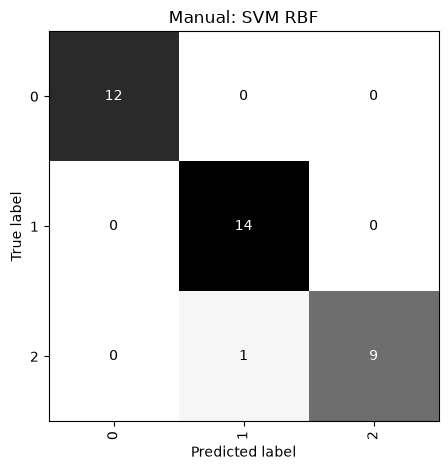


 FLAML 
               precision    recall  f1-score   support

           0       0.92      1.00      0.96        12
           1       1.00      0.93      0.96        14
           2       1.00      1.00      1.00        10

    accuracy                           0.97        36
   macro avg       0.97      0.98      0.97        36
weighted avg       0.97      0.97      0.97        36



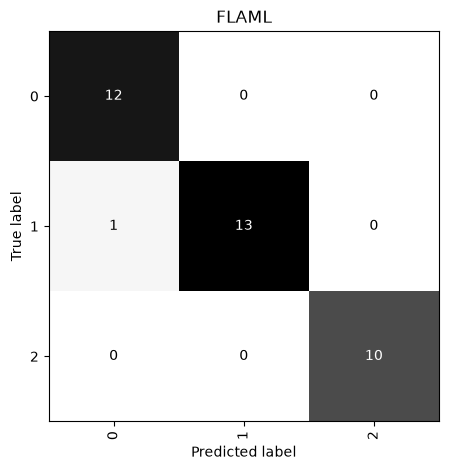


 TPOT 
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        12
           1       0.93      1.00      0.97        14
           2       1.00      0.90      0.95        10

    accuracy                           0.97        36
   macro avg       0.98      0.97      0.97        36
weighted avg       0.97      0.97      0.97        36



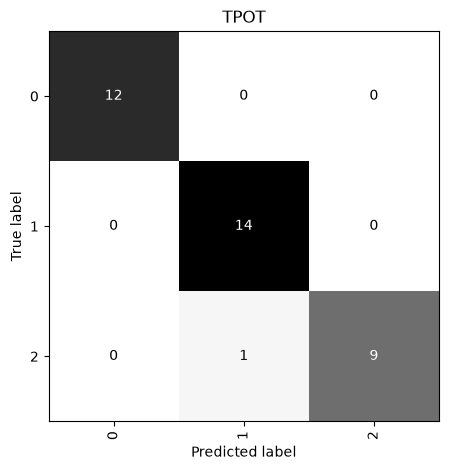

,Modelo,Acurácia teste,F1 macro teste,Tempo de predição (s)
0,Manual: SVM RBF,0.9722,0.9710,0.0051
1,FLAML,0.9722,0.9743,0.0043
2,TPOT,0.9722,0.9710,0.0023


In [34]:
best2=results2.iloc[0]['Modelo']
finalists2={f'Manual: {best2}':clone(models2[best2])}
if flaml2 is not None:finalists2['FLAML']=flaml2
if tpot2 is not None:finalists2['TPOT']=tpot2
report2=[]
for name,model in finalists2.items():
    try:
        t=time.perf_counter()
        if name.startswith('Manual:'):model.fit(X2tr,y2tr)
        p=model.predict(X2te)
        report2.append({'Modelo':name,'Acurácia teste':accuracy_score(y2te,p),
                        'F1 macro teste':f1_score(y2te,p,average='macro'),
                        'Tempo de predição (s)':time.perf_counter()-t})
        print('\n',name,'\n',classification_report(y2te,p,zero_division=0))
        ConfusionMatrixDisplay.from_predictions(y2te,p,xticks_rotation='vertical', cmap='Greys', values_format='d', colorbar=False)
        plt.title(name);plt.tight_layout();plt.show()
    except Exception as e:print('Falha:',name,repr(e))
report2_df=pd.DataFrame(report2)
display(report2_df.round(4))

## 11. Ficha de análise do dataset escolhido — preencher no notebook
**Identificação:** nome do dataset, fonte/URL, licença, data de acesso, objetivo da classificação, unidade amostral.

**Qualidade dos dados:** número de observações e atributos, distribuição das classes, ausências, duplicatas, risco de vazamento, eventuais restrições éticas.

**Método:** proporção treino/teste, semente, número de folds, métrica principal, tempo de busca, versões do Python e bibliotecas, eventuais erros de execução.

**Resultados:** tabela de baselines, configurações escolhidas pelo FLAML/TPOT, desempenho de teste, matrizes de confusão, tempo de busca.

**Discussão:** quais classes são mais difíceis? Qual a estabilidade? O AutoML compensou o custo? Há indícios de sobreajuste? Que modelo você recomenda e por quê? Quais limitações permanecem?

Ficha:

Identificação: Wine (UCI, carregado pelo sklearn.datasets.load_wine). link: https://archive.ics.uci.edu/dataset/109/wine, licença CC BY 4.0, acesso em 09/11/2026. Objetivo: classificar de qual dos 3 produtores (cultivares) da Itália o vinho veio a partir de análise quimica. Cada linha é uma amostra de vinho.

Qualidade dos dados: 178 amostras, 13 atributos numéricos. Classes: 0=59, 1=71, 2=48 (um pouco desequilibrado). Sem valores ausentes. Não tem dado pessoal nem problema ético. Não vi risco de vazamento, todas as variaveis são medidas quimicas.

Método: 80/20 estratificado (142 treino / 36 teste), seed 42, 5 folds, métrica F1 macro. FLAML com 90s e TPOT com 5 min / 3 gerações. Python 3.13.7, scikit-learn 1.9.1, FLAML 2.8.0, TPOT 1.1.0.

Resultados: melhor baseline foi SVM RBF (CV 0.9865). FLAML escolheu extra_tree (12 árvores, max_leaves 7). TPOT escolheu MinMaxScaler + VarianceThreshold + regressão logística elasticnet (C≈3.4). No teste os três tiveramm acurácia 0.9722 (1 erro cada): SVM RBF F1 0.9710, FLAML 0.9743 e TPOT 0.9710.

Discussão: as classes 1 e 2 são as que confundem mais (SVM e TPOT erraram uma 2 como 1, o FLAML errou uma 1 como 0). Os modelos com escala (SVM, logistica) foram estaveis, a árvore de decisão e o gradient boosting variaram mais (desvio 0.057 e 0.10). O AutoML não adiantou muita cois, empatou com um SVM que treina em milissegundos. Não vi sinal de sobreajuste, CV e teste ficaram parecidos. Recomendo o SVM RBF com StandardScaler. Limitação: o teste é pequeno (36), então 1 erro pra mais ou pra menos muda bastante.

## 12. Questões finais — respostas obrigatórias
1. Qual problema real seu dataset representa e por que a classificação é adequada?
2. O dataset é equilibrado? Qual impacto disso na escolha de F1 macro?
3. Qual baseline venceu na CV? A vantagem foi consistente?
4. Quais algoritmos e hiperparâmetros FLAML e TPOT selecionaram? Houve erros ou restrições?
5. Qual foi o desempenho dos finalistas no teste **não usado para seleção**?
6. Quais classes tiveram maior taxa de erro? Mostre evidências na matriz de confusão.
7. Um modelo mais complexo trouxe ganho relevante?
8. Que riscos de vazamento, sobreajuste e generalização você identificou?
9. Qual modelo recomendaria para aplicação e com quais ressalvas?
10. Por que o resultado no Iris não determina o melhor algoritmo no seu dataset?

### Critérios de avaliação (10,0 pontos)
- Exploração e descrição dos dois datasets: **1,5**
- Baselines e validação cruzada: **2,0**
- FLAML e TPOT (execução, configuração ou diagnóstico técnico fundamentado): **2,0**
- Comparação de métricas, matrizes e tempos: **2,0**
- Discussão crítica e escolha fundamentada: **2,0**
- Reprodutibilidade e organização do notebook: **0,5**

**Entrega:** arquivo `.ipynb` com células executadas, respostas em Markdown, fonte do dataset e conclusões. Se uma biblioteca falhar por incompatibilidade, registre versões, erro e tentativa de solução; não apresente métricas inexistentes.

Respostas finais:

1. Identificar o produtor de um vinho pela composição quimica, tipo um controle de origem. É classificação porque o alvo é uma categoria (3 produtores).
2. Mais ou menos, 71/59/48. Não é muito desequilibrado, mas o F1 macro ajuda porque da o mesmo peso pra classe que é minoritária (48).
3. SVM RBF com 0.9865, mas o SVM linear ficou com 0.9863, praticamente igual. A vantagem não é consistente, a diferença é bem menor que o desvio.
4. FLAML: no Iris extra_tree (12 árvores, max_leaves=4, entropy), no Wine extra_tree (n_estimators=12, max_features≈0.21, max_leaves=7, gini). TPOT: no Iris KNN (12 vizinhos, p=3) com FastICA, no Wine MinMaxScaler + VarianceThreshold + regressão logística elastiet (C≈3.4, l1_ratio≈0.67).
5. Wine: os três com acurácia 0.9722. F1 macro: SVM RBF 0.9710, FLAML 0.9743, TPOT 0.9710.
6. No SVM e no TPOT o erro foi na classe 2 (recall 0.90), um exemplo foi pra classe 1. No FLAML o erro foi na classe 1 (recall 0.93), foi pra classe 0. Da pra ver nas matrizes de confusão acima.
7. Não. O FLAML e o TPOT deram praticamente o mesmo resultado do SVM, e o gradient boosting (mais complexo) foi um dos piores na CV.
8. Vazamento evitei deixando o scaler e o imputer dentro do pipeline e só olhando o teste no final. Sobreajuste não apareceu muito, mas a árvore de decisão sozinha ficou bem pior (0.9055). Generalização é limitada porque o dataset é pequeno e de uma região só.
9. SVM RBF com padronização. Ressalva: só foi testado com 36 exemplos e com vinhos desses 3 produtores, então não serve pra vinho de outro lugar.
10. Porque cada dataset tem uma estrutura diferente. No Iris ganhou o SVM linear e no Wine o RBF, e o FLAML e o TPOT escolheram configurações diferentes em cada um. Não existe um algoritmo melhor pra tudo.

## Leituras e documentação
- [scikit-learn — Iris](https://scikit-learn.org/stable/auto_examples/datasets/plot_iris_dataset.html)
- [scikit-learn — Cross-validation](https://scikit-learn.org/stable/modules/cross_validation.html)
- [scikit-learn — Métricas](https://scikit-learn.org/stable/modules/model_evaluation.html)
- [FLAML — documentação](https://microsoft.github.io/FLAML/)
- [TPOT — documentação](https://epistasislab.github.io/tpot/)

**Nota de reprodutibilidade:** execute `pip freeze` e salve as versões se desejar reproduzir exatamente o ambiente. Resultados dependem de versões, orçamento, máquina e sementes.

In [35]:
# Opcional: salvar informações do ambiente para o relatório
import subprocess
print(subprocess.run([sys.executable,'-m','pip','freeze'],capture_output=True,text=True).stdout[:12000])

alembic==1.20.1
appnope==1.0.0
asttokens==3.0.2
attrs==26.1.0
beautifulsoup4==4.15.0
bleach==6.4.0
cffi==2.1.1
click==8.5.1
cloudpickle==3.1.2
colorlog==6.12.0
comm==0.2.3
ConfigSpace==1.2.2
contourpy==1.4.0
cycler==0.12.1
dask==2026.8.0
dask-expr==2.0.0
dask-jobqueue==0.9.0
deap==1.4.4
debugpy==1.8.22
defusedxml==0.7.1
dill==0.4.1
distributed==2026.8.0
executing==2.3.0
fastjsonschema==2.22.3
FLAML==2.8.0
fonttools==4.68.0
fsspec==2026.9.0
func_timeout==4.3.5
ipykernel==7.4.0
ipython==9.18.1
ipython_pygments_lexers==1.1.1
jedi==0.20.1
Jinja2==3.1.6
joblib==1.6.0
jsonschema==4.26.0
jsonschema-specifications==2025.9.1
jupyter_client==8.10.0
jupyter_core==5.9.1
jupyterlab_pygments==0.3.0
kiwisolver==1.5.1
lightgbm==4.7.0
locket==1.0.0
Mako==1.4.3
MarkupSafe==3.0.4
matplotlib==3.11.2
matplotlib-inline==0.2.2
mistune==3.4.0
moocore==0.3.2
more-itertools==11.2.1
msgpack==1.2.4
narwhals==2.28.0
nbclient==0.11.0
nbconvert==7.17.2
nbformat==5.11.1
nest-asyncio2==1.7.4
networkx==3.7
numpy==2.5.4